In [4]:
!pip -q install copernicusmarine

In [5]:
import os, json, math, time, warnings, getpass
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount("/content/drive")

BASE   = "/content/drive/MyDrive/Marine-Plastic-AI"
RAW    = f"{BASE}/data/raw"
PROC   = f"{BASE}/data/processed"
FIG    = f"{BASE}/outputs/figures"
TAB    = f"{BASE}/outputs/tables"
MODELS = f"{BASE}/models"
for p in [f"{RAW}/obis", f"{RAW}/coral_atlas", f"{RAW}/copernicus", PROC, FIG, TAB, MODELS]:
    os.makedirs(p, exist_ok=True)

SEED = 42
rng  = np.random.default_rng(SEED)

POLY = [(78.356112, 9.17125),    # west
        (80.06426, 10.021422),   # north
        (80.419466, 9.335989),   # east
        (79.818754, 7.719526)]   # south
_lons, _lats = zip(*POLY)
PAD = 0.1
BBOX = dict(lon_min=min(_lons) - PAD, lon_max=max(_lons) + PAD,
            lat_min=min(_lats) - PAD, lat_max=max(_lats) + PAD)

RADIUS_KM = 10

END_DATE   = pd.Timestamp.today().normalize() - pd.Timedelta(days=12)   # analysis data lags a few days
N_DAYS     = 60
START_DATE = END_DATE - pd.Timedelta(days=N_DAYS - 1)

WEIGHTS = dict(pollution=0.40, biodiversity=0.25, habitat=0.25, environment=0.10)
LABELS  = ["Low", "Medium", "High"]
N_SCENARIOS = 20
HORIZONS = [1, 3]

PLASTIC_CSV = f"{PROC}/plastic_predictions.csv"
PLASTIC_COL = "plastic_coverage"

def savefig(name):
    plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

print("Study window:", START_DATE.date(), "->", END_DATE.date())
print("Download box:", {k: round(v, 2) for k, v in BBOX.items()})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Study window: 2026-08-04 -> 2026-10-02
Download box: {'lon_min': 78.26, 'lon_max': 80.52, 'lat_min': 7.62, 'lat_max': 10.12}


In [6]:
import xarray as xr
import copernicusmarine as cm

print("copernicusmarine version:", cm.__version__)
cm.login(username=input("Copernicus username: "),
         password=getpass.getpass("Copernicus password: "),
         force_overwrite=True)

IDS = dict(
    cur    = ("cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m",    ["uo", "vo"], True),
    thetao = ("cmems_mod_glo_phy-thetao_anfc_0.083deg_P1D-m", ["thetao"],   True),
    wav    = ("cmems_mod_glo_wav_anfc_0.083deg_PT3H-i",       ["VHM0"],     False),
)

def fetch(name):
    dsid, variables, has_depth = IDS[name]
    path = f"{RAW}/copernicus/{name}_{START_DATE.date()}_{END_DATE.date()}.nc"
    if os.path.exists(path):
        print(f"{name}: loaded from Drive cache")
        return xr.open_dataset(path).load()
    print(f"{name}: downloading ...")
    kw = dict(dataset_id=dsid, variables=variables,
              minimum_longitude=BBOX["lon_min"], maximum_longitude=BBOX["lon_max"],
              minimum_latitude=BBOX["lat_min"],  maximum_latitude=BBOX["lat_max"],
              start_datetime=str(START_DATE.date()), end_datetime=f"{END_DATE.date()}T23:59:59")
    if has_depth:
        kw.update(minimum_depth=0, maximum_depth=1)
    ds = cm.open_dataset(**kw).load()
    if "depth" in ds.dims:
        ds = ds.isel(depth=0, drop=True)
    ds.to_netcdf(path)
    return ds

data = {}
for name in ["cur", "thetao", "wav"]:
    try:
        data[name] = fetch(name)
        print(f"  OK  {name}: {dict(data[name].sizes)}")
    except Exception as e:
        print(f"  FAILED {name}: {type(e).__name__}: {str(e)[:500]}")

if len(data) == 3:
    cur, thetao, wav = data["cur"], data["thetao"], data["wav"]
    print("\nAll three datasets ready. Go on to Cell 4.")

copernicusmarine version: 2.5.0
Copernicus username: anannya.jadhav
Copernicus password: ··········


INFO - 2026-10-14T09:26:06Z - Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.
INFO:copernicusmarine:Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.


cur: downloading ...


INFO - 2026-10-14T09:26:09Z - Selected dataset version: "202406"
INFO:copernicusmarine:Selected dataset version: "202406"
INFO - 2026-10-14T09:26:09Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-14T09:26:09Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


  OK  cur: {'latitude': 30, 'longitude': 27, 'time': 60}
thetao: downloading ...


INFO - 2026-10-14T09:26:16Z - Selected dataset version: "202406"
INFO:copernicusmarine:Selected dataset version: "202406"
INFO - 2026-10-14T09:26:16Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-14T09:26:16Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


  OK  thetao: {'latitude': 30, 'longitude': 27, 'time': 60}
wav: downloading ...


INFO - 2026-10-14T09:26:22Z - Selected dataset version: "202411"
INFO:copernicusmarine:Selected dataset version: "202411"
INFO - 2026-10-14T09:26:22Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"


  OK  wav: {'time': 480, 'latitude': 30, 'longitude': 27}

All three datasets ready. Go on to Cell 4.


245 sites | 60 days | grid cell ≈ 9.2 km
share of missing values before filling: {'U': 0.0, 'V': 0.0, 'T': 0.0, 'W': 0.061}
mean current 0.122 m/s | mean SST 29.02 °C | mean wave height 1.28 m


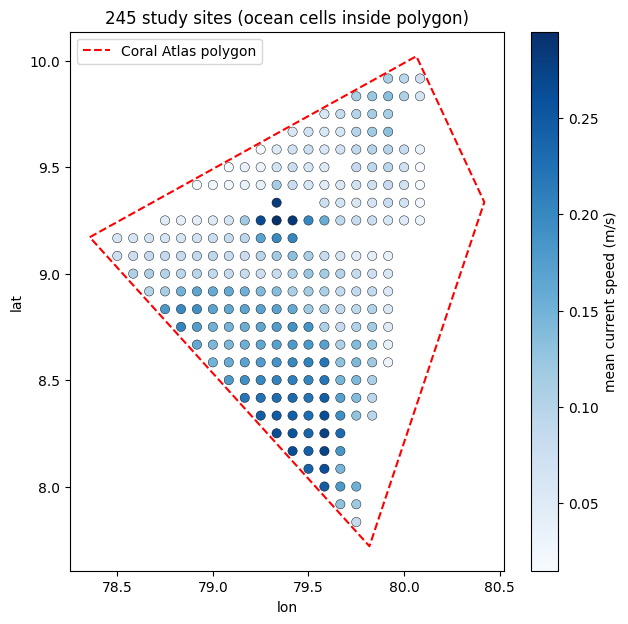

In [7]:
from sklearn.neighbors import BallTree
from matplotlib.path import Path as MPath

# ---- align everything to daily values on the currents grid ----
wav = wav.resample(time="1D").mean()                  # 3-hourly waves -> daily mean
day = lambda ds: ds.assign_coords(time=ds["time"].dt.floor("D"))
cur, thetao, wav = day(cur), day(thetao), day(wav)
thetao = thetao.interp(latitude=cur.latitude, longitude=cur.longitude, method="nearest").reindex(time=cur.time, method="nearest")
wav    = wav.interp(latitude=cur.latitude, longitude=cur.longitude, method="nearest").reindex(time=cur.time, method="nearest")

order = ("time", "latitude", "longitude")
uo, vo = cur.uo.transpose(*order), cur.vo.transpose(*order)
th, hs = thetao.thetao.transpose(*order), wav.VHM0.transpose(*order)

# ---- study sites = ocean cells with valid currents AND inside your Atlas polygon ----
valid  = (uo.notnull().mean("time") > 0.9).values
iy, ix = np.where(valid)
lat_c, lon_c = cur.latitude.values[iy], cur.longitude.values[ix]
inside = MPath(POLY + [POLY[0]]).contains_points(np.c_[lon_c, lat_c])
iy, ix, lat_c, lon_c = iy[inside], ix[inside], lat_c[inside], lon_c[inside]

sites = pd.DataFrame({"site_id": [f"S{i:03d}" for i in range(len(iy))], "lat": lat_c, "lon": lon_c})
CELL_DEG = float(np.abs(np.diff(cur.latitude.values)).mean())
CELL_KM  = CELL_DEG * 111.0

U, V, T, W = (a.values[:, iy, ix] for a in (uo, vo, th, hs))      # shape [time, site]

def fill_missing(arr, sites):
    """Interpolate small gaps in time; sites with no data at all copy the nearest valid site."""
    arr = pd.DataFrame(arr).interpolate(limit_direction="both").values
    bad = np.isnan(arr).all(axis=0)
    if bad.any():
        good = np.where(~bad)[0]
        tree = BallTree(np.radians(sites.iloc[good][["lat", "lon"]].values), metric="haversine")
        _, j = tree.query(np.radians(sites.loc[bad, ["lat", "lon"]].values), k=1)
        arr[:, bad] = arr[:, good[j[:, 0]]]
    return arr

nan_share = {n: float(np.isnan(a).mean().round(3)) for n, a in zip("UVTW", (U, V, T, W))}
U, V, T, W = (fill_missing(a, sites) for a in (U, V, T, W))
SPEED = np.hypot(U, V)
dates = pd.to_datetime(cur.time.values)

print(f"{len(sites)} sites | {len(dates)} days | grid cell ≈ {CELL_KM:.1f} km")
print("share of missing values before filling:", nan_share)
print(f"mean current {SPEED.mean():.3f} m/s | mean SST {T.mean():.2f} °C | mean wave height {W.mean():.2f} m")

sites.to_csv(f"{PROC}/sites.csv", index=False)
np.savez_compressed(f"{PROC}/ocean_arrays.npz", U=U, V=V, T=T, W=W, dates=dates.astype(str).values)
json.dump(dict(cell_deg=CELL_DEG, cell_km=CELL_KM), open(f"{PROC}/grid_info.json", "w"))

# ---- sanity plot: sites inside the polygon ----
px, py = zip(*(POLY + [POLY[0]]))
plt.figure(figsize=(7, 7))
sc = plt.scatter(sites.lon, sites.lat, c=SPEED.mean(0), cmap="Blues", s=45, edgecolor="k", linewidth=.3)
plt.plot(px, py, "r--", label="Coral Atlas polygon"); plt.colorbar(sc, label="mean current speed (m/s)")
plt.legend(); plt.xlabel("lon"); plt.ylabel("lat"); plt.title(f"{len(sites)} study sites (ocean cells inside polygon)")
savefig("00_study_sites")

In [8]:
import requests

def fetch_obis(poly, max_records=250_000, page=5000, start_year=2000):
    ring = poly + [poly[0]]
    wkt = "POLYGON((" + ",".join(f"{x} {y}" for x, y in ring) + "))"
    rows, after = [], None
    while len(rows) < max_records:
        params = dict(geometry=wkt, size=page, startdate=f"{start_year}-01-01",
                      fields="id,scientificName,decimalLatitude,decimalLongitude,date_year,depth,class,phylum,redlist_category")
        if after:
            params["after"] = after
        for attempt in range(3):                              # retry a few times on network hiccups
            try:
                r = requests.get("https://api.obis.org/v3/occurrence", params=params, timeout=180)
                r.raise_for_status()
                break
            except Exception as e:
                print(f"\n  retry {attempt + 1}/3 after error: {str(e)[:120]}")
                time.sleep(5)
        else:
            print("\n⚠️ Giving up after 3 failed retries; keeping what was downloaded so far.")
            break
        res = r.json().get("results", [])
        if not res:
            break
        rows += res
        after = res[-1]["id"]
        print(f"  downloaded {len(rows):,} records", end="\r")
    return pd.DataFrame(rows)

OBIS_PATH = f"{RAW}/obis/obis_raw.csv"
if os.path.exists(OBIS_PATH):
    obis_raw = pd.read_csv(OBIS_PATH)
    print("loaded OBIS from Drive cache")
else:
    obis_raw = fetch_obis(POLY)
    obis_raw.to_csv(OBIS_PATH, index=False)
print(f"\nraw OBIS records: {len(obis_raw):,}")
obis_raw.head()

loaded OBIS from Drive cache

raw OBIS records: 6,208


,class,date_year,decimalLatitude,decimalLongitude,phylum,scientificName,id,depth
0,Bivalvia,2006,8.953200,78.886700,Mollusca,Sunetta scripta,000fd696-dab8-4e3b-b197-e5b7fad0e0fb,NaN
1,Demospongiae,2019,9.243500,79.190000,Porifera,Monanchora,00149cd6-8b72-4bff-9b4f-22450f3bd69f,3.5
2,Aves,2025,8.462509,79.790625,Chordata,Sterna bergii,00287154-e5be-47a3-b418-e0522492b66b,NaN
3,Gastropoda,2016,9.287584,79.312949,Mollusca,Monetaria annulus,003066f1-062f-415d-994d-33a5cd2ca5cc,NaN
4,Demospongiae,2019,9.159000,78.730100,Porifera,Spheciospongia incrustans,003c7e13-cb63-462f-9a25-2ccb919a8522,2.5


In [9]:
def clean_obis(df, poly):
    d = df.copy()
    n0 = len(d)
    d = d.dropna(subset=["decimalLatitude", "decimalLongitude", "scientificName"])
    d = d[~((d.decimalLatitude == 0) & (d.decimalLongitude == 0))]
    ring = poly + [poly[0]]
    d = d[MPath(ring).contains_points(d[["decimalLongitude", "decimalLatitude"]].values)]   # keep only points inside polygon
    if "depth" in d:
        d = d[d.depth.isna() | (d.depth <= 200)]                                            # shallow water only
    d = d[d.scientificName.str.contains(" ", regex=False)]                                  # species-level names (binomials)
    d = d.drop_duplicates(subset=["scientificName", "decimalLatitude", "decimalLongitude", "date_year"])
    print(f"cleaning: {n0:,} -> {len(d):,} records | {d.scientificName.nunique():,} unique species")
    return d.reset_index(drop=True)

obis = clean_obis(obis_raw, POLY)
for col in ["redlist_category", "class"]:
    if col not in obis:
        obis[col] = np.nan
print("\nTop classes:"); print(obis["class"].value_counts().head(8))
print("\nRed List categories:"); print(obis["redlist_category"].value_counts(dropna=False))
obis.to_csv(f"{PROC}/obis_clean.csv", index=False)

cleaning: 6,208 -> 5,254 records | 3,536 unique species

Top classes:
class
Teleostei       752
Aves            724
Demospongiae    682
Gastropoda      561
Malacostraca    451
Bivalvia        242
Copepoda        219
Polychaeta      191
Name: count, dtype: int64

Red List categories:
redlist_category
NaN    5254
Name: count, dtype: int64


sites with zero OBIS records nearby: 115 of 245


,n_records,species_richness,n_classes,sensitive_species,record_density
count,245.00,245.00,245.00,245.0,245.00
mean,74.96,66.63,2.77,0.0,0.24
std,388.28,385.60,5.81,0.0,1.24
min,0.00,0.00,0.00,0.0,0.00
25%,0.00,0.00,0.00,0.0,0.00
50%,1.00,1.00,1.00,0.0,0.00
75%,15.00,14.00,3.00,0.0,0.05
max,3027.00,3027.00,39.00,0.0,9.64


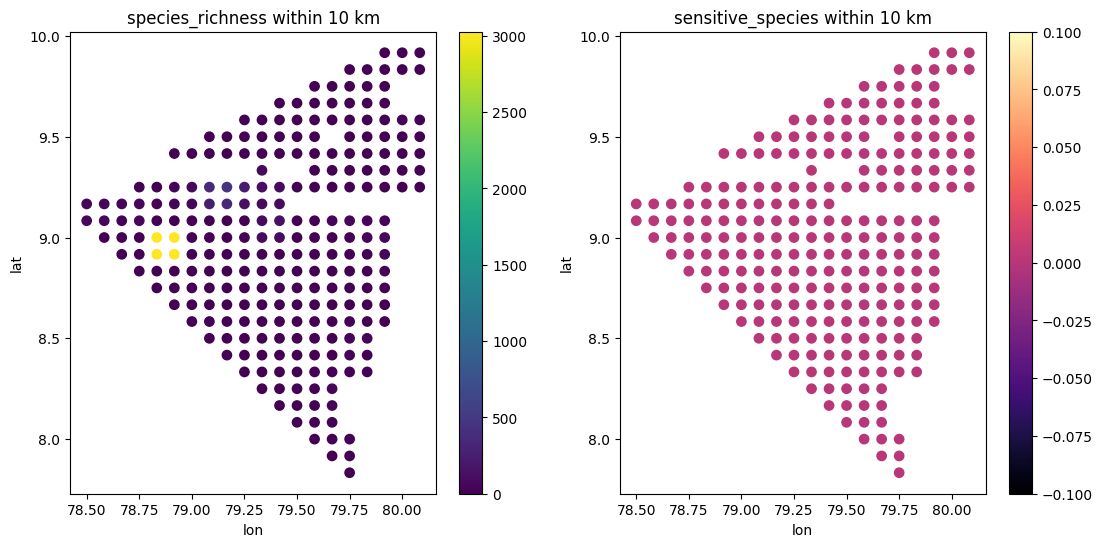

In [10]:
SENSITIVE_CATS = ["VU", "EN", "CR"]        # IUCN Vulnerable / Endangered / Critically endangered

def obis_features(sites, obis, radius_km=RADIUS_KM):
    tree = BallTree(np.radians(obis[["decimalLatitude", "decimalLongitude"]].values), metric="haversine")
    ind  = tree.query_radius(np.radians(sites[["lat", "lon"]].values), r=radius_km / 6371.0088)
    area = math.pi * radius_km ** 2
    rows = []
    for idx in ind:
        sub = obis.iloc[idx]
        rows.append(dict(n_records=len(sub),
                         species_richness=sub.scientificName.nunique(),
                         n_classes=sub["class"].nunique(),
                         sensitive_species=sub.loc[sub.redlist_category.isin(SENSITIVE_CATS), "scientificName"].nunique(),
                         record_density=len(sub) / area))
    return pd.DataFrame(rows, index=sites.index)

bio_feats = obis_features(sites, obis)
print("sites with zero OBIS records nearby:", int((bio_feats.n_records == 0).sum()), "of", len(sites))
display(bio_feats.describe().round(2))

bio_feats.assign(site_id=sites.site_id).to_csv(f"{PROC}/obis_features.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for a, col, cmap in zip(ax, ["species_richness", "sensitive_species"], ["viridis", "magma"]):
    s = a.scatter(sites.lon, sites.lat, c=bio_feats[col], cmap=cmap, s=45); plt.colorbar(s, ax=a)
    a.set_title(f"{col} within {RADIUS_KM} km"); a.set_xlabel("lon"); a.set_ylabel("lat")
savefig("01_obis_maps")

In [11]:
import os, glob
for root in ["/content", "/content/drive/MyDrive", RAW]:
    if os.path.exists(root):
        hits = glob.glob(f"{root}/**/*.geojson", recursive=True) + \
               glob.glob(f"{root}/**/*.zip", recursive=True) + \
               glob.glob(f"{root}/**/*.gpkg", recursive=True)
        print(f"\n{root}:")
        for h in hits[:40]:
            print(f"   {os.path.getsize(h)/1e6:8.1f} MB  {h}")
    else:
        print(f"\n{root}: does not exist")


/content:
      201.5 MB  /content/drive/MyDrive/coral atlas/Area-20260919192616/Benthic-Map/benthic.geojson
        0.0 MB  /content/drive/MyDrive/coral atlas/Area-20260919192616/boundary/boundary.geojson
        4.2 MB  /content/drive/MyDrive/Classroom/SY BTech DBMS Lab B3 & B4/Hospital-Management-System-dbmsminiproject-main (1).zip
        0.0 MB  /content/drive/MyDrive/mini project/online cab booking.zip

/content/drive/MyDrive:
      201.5 MB  /content/drive/MyDrive/coral atlas/Area-20260919192616/Benthic-Map/benthic.geojson
        0.0 MB  /content/drive/MyDrive/coral atlas/Area-20260919192616/boundary/boundary.geojson
        4.2 MB  /content/drive/MyDrive/Classroom/SY BTech DBMS Lab B3 & B4/Hospital-Management-System-dbmsminiproject-main (1).zip
        0.0 MB  /content/drive/MyDrive/mini project/online cab booking.zip

/content/drive/MyDrive/Marine-Plastic-AI/data/raw:


In [12]:
import glob, zipfile
import geopandas as gpd
from scipy.spatial import cKDTree

LIGHT_PATH = f"{PROC}/coral_polygons_light.csv"

def find_benthic():
    roots = ["/content", "/content/drive/MyDrive", RAW]
    pats  = ["**/*benthic*.geojson", "**/*benthic*.gpkg", "**/*benthic*.shp",
             "**/benthic*/*.geojson", "**/*.geojson"]
    cands = []
    for r in roots:
        if not os.path.exists(r):
            continue
        for p in pats:
            cands += glob.glob(os.path.join(r, p), recursive=True)
    cands = [c for c in set(cands) if os.path.getsize(c) > 1e6]      # ignore tiny files
    if cands:
        return max(cands, key=os.path.getsize)                       # the Atlas file is the big one
    # nothing yet: try unzipping an Atlas archive
    zips = [z for r in roots if os.path.exists(r)
              for z in glob.glob(os.path.join(r, "**/*.zip"), recursive=True)]
    for z in zips:
        with zipfile.ZipFile(z) as f:
            names = [n for n in f.namelist() if n.lower().endswith((".geojson", ".gpkg"))]
            if names:
                print("unzipping", z)
                f.extractall("/content/atlas_unzipped")
                return f"/content/atlas_unzipped/{names[0]}"
    return None

if os.path.exists(LIGHT_PATH):
    light = pd.read_csv(LIGHT_PATH)
    print("loaded cached habitat table from Drive")
else:
    path = find_benthic()
    assert path, "Still not found — paste the output of the diagnostic cell above."
    print("reading", path, f"({os.path.getsize(path)/1e6:.0f} MB) ... 1-3 minutes")
    g = gpd.read_file(path)
    print("polygons:", len(g), "| columns:", list(g.columns), "| crs:", g.crs)
    CLASS_COL = next(c for c in ["class", "Class", "CLASS"] if c in g.columns)
    g = g.to_crs(32644)
    cen = g.geometry.centroid
    light = pd.DataFrame({"cls": g[CLASS_COL].values, "x": cen.x.values,
                          "y": cen.y.values, "area_m2": g.geometry.area.values})
    light.to_csv(LIGHT_PATH, index=False)
    del g, cen
    print("saved a compact habitat table to Drive")

loaded cached habitat table from Drive


sites with coral/algae inside the radius: 106 of 245
sites with seagrass inside the radius   : 96 of 245


,mapped_frac,coral_cover_frac,seagrass_frac,habitat_sens,coral_dist_km
count,245.000,245.000,245.000,245.000,245.000
mean,0.052,0.007,0.008,0.024,17.465
std,0.107,0.018,0.026,0.054,15.439
min,0.000,0.000,0.000,0.000,0.023
25%,0.000,0.000,0.000,0.000,5.242
50%,0.000,0.000,0.000,0.000,12.702
75%,0.041,0.005,0.001,0.021,27.801
max,0.545,0.149,0.225,0.366,50.000


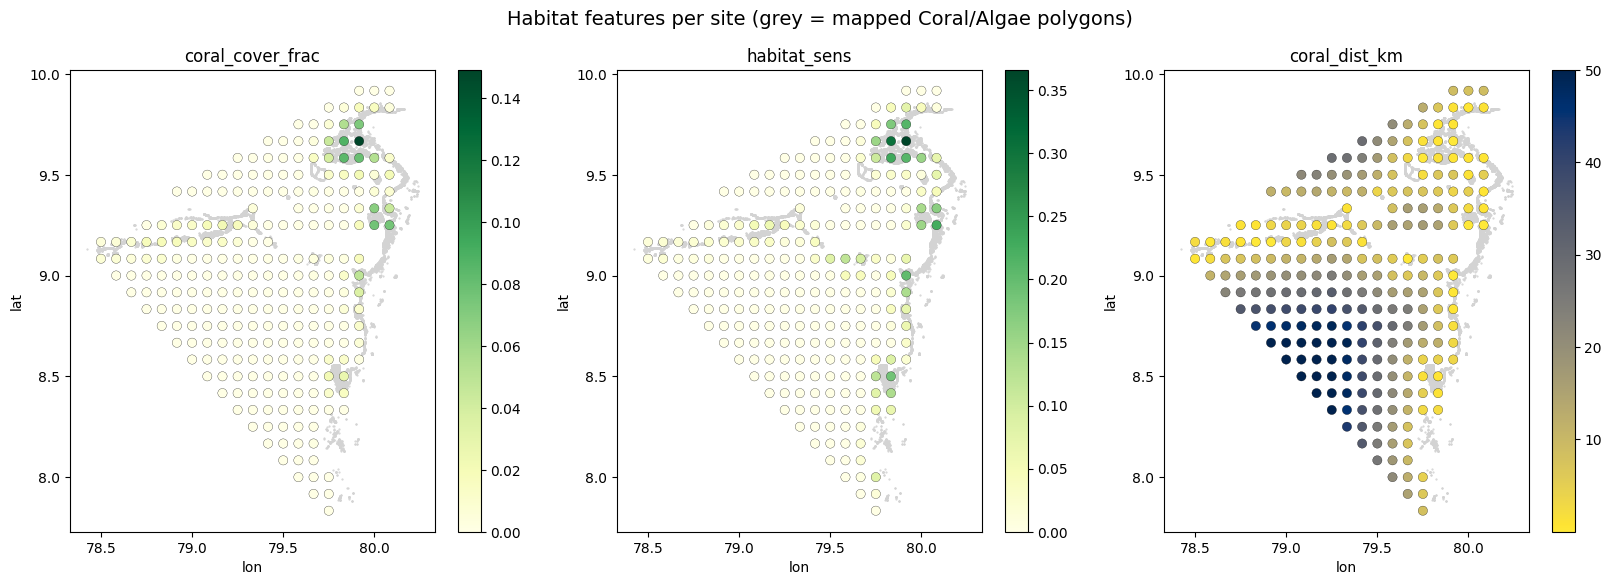

In [13]:
from pyproj import Transformer
from scipy.spatial import cKDTree

# ---- sensitivity weight per habitat class (assumption; explain in report) ----
BENTHIC_SENS = {"coral": 1.0, "seagrass": 0.8, "rubble": 0.4, "rock": 0.3, "sand": 0.1}
def class_weight(name):
    n = str(name).lower()
    return next((w for k, w in BENTHIC_SENS.items() if k in n), 0.2)

light["w"] = light.cls.map(class_weight)
is_coral   = light.cls.str.contains("coral", case=False).values
is_seagras = light.cls.str.contains("seagrass", case=False).values
P    = light[["x", "y"]].values
area = light.area_m2.values
wts  = light.w.values

to_utm = Transformer.from_crs(4326, 32644, always_xy=True)
sx, sy = to_utm.transform(sites.lon.values, sites.lat.values)
S = np.c_[sx, sy]

R = RADIUS_KM * 1000
circle_area = math.pi * R ** 2
tree_all = cKDTree(P)
ind = tree_all.query_ball_point(S, r=R)                 # habitat polygons (by centroid) within the radius of each site

rows = []
for idx in ind:
    idx = np.asarray(idx, dtype=int)
    a = area[idx]
    rows.append(dict(mapped_frac=a.sum() / circle_area,
                     coral_cover_frac=a[is_coral[idx]].sum() / circle_area,
                     seagrass_frac=a[is_seagras[idx]].sum() / circle_area,
                     habitat_sens=(a * wts[idx]).sum() / circle_area))
coral_feats = pd.DataFrame(rows, index=sites.index)

d_coral, _ = cKDTree(P[is_coral]).query(S)                # distance to nearest Coral/Algae polygon
coral_feats["coral_dist_km"] = np.clip(d_coral / 1000, 0, 50)

print("sites with coral/algae inside the radius:", int((coral_feats.coral_cover_frac > 0).sum()), "of", len(sites))
print("sites with seagrass inside the radius   :", int((coral_feats.seagrass_frac > 0).sum()), "of", len(sites))
display(coral_feats.describe().round(3))
coral_feats.assign(site_id=sites.site_id).to_csv(f"{PROC}/coral_features.csv", index=False)

# ---- maps ----
to_ll = Transformer.from_crs(32644, 4326, always_xy=True)
samp = np.random.default_rng(SEED).choice(np.where(is_coral)[0], size=min(30000, is_coral.sum()), replace=False)
clon, clat = to_ll.transform(P[samp, 0], P[samp, 1])
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for a_, col, cmap in zip(ax, ["coral_cover_frac", "habitat_sens", "coral_dist_km"], ["YlGn", "YlGn", "cividis_r"]):
    a_.scatter(clon, clat, s=0.3, c="lightgrey", zorder=0)                       # grey dots = mapped Coral/Algae
    s = a_.scatter(sites.lon, sites.lat, c=coral_feats[col], cmap=cmap, s=45, edgecolor="k", linewidth=.2, zorder=2)
    plt.colorbar(s, ax=a_); a_.set_title(col); a_.set_xlabel("lon"); a_.set_ylabel("lat")
plt.suptitle("Habitat features per site (grey = mapped Coral/Algae polygons)", fontsize=14)
savefig("02_habitat_maps")

master site table: (245, 17)


,site_id,lat,lon,n_records,species_richness,n_classes,sensitive_species,record_density,mapped_frac,coral_cover_frac,seagrass_frac,habitat_sens,coral_dist_km,current_speed,current_dir,temperature,wave_height
0,S000,7.833336,79.750000,8,7,2,0,0.025465,0.000440,0.000078,0.000134,0.000262,8.193935,0.084142,359.097839,29.064880,1.584021
1,S001,7.916672,79.666687,1,1,1,0,0.003183,0.000000,0.000000,0.000000,0.000000,15.161915,0.131222,354.152313,28.794622,1.737187
2,S002,7.916672,79.750000,9,8,4,0,0.028648,0.061886,0.000103,0.009378,0.013406,6.497130,0.120966,357.615173,29.149118,1.639437
3,S003,8.000000,79.583344,1,1,1,0,0.003183,0.000000,0.000000,0.000000,0.000000,21.149957,0.245688,12.529541,28.095398,1.824667
4,S004,8.000000,79.666687,15,13,6,0,0.047746,0.025097,0.000000,0.003886,0.005232,12.260917,0.180933,2.504791,28.891474,1.712708


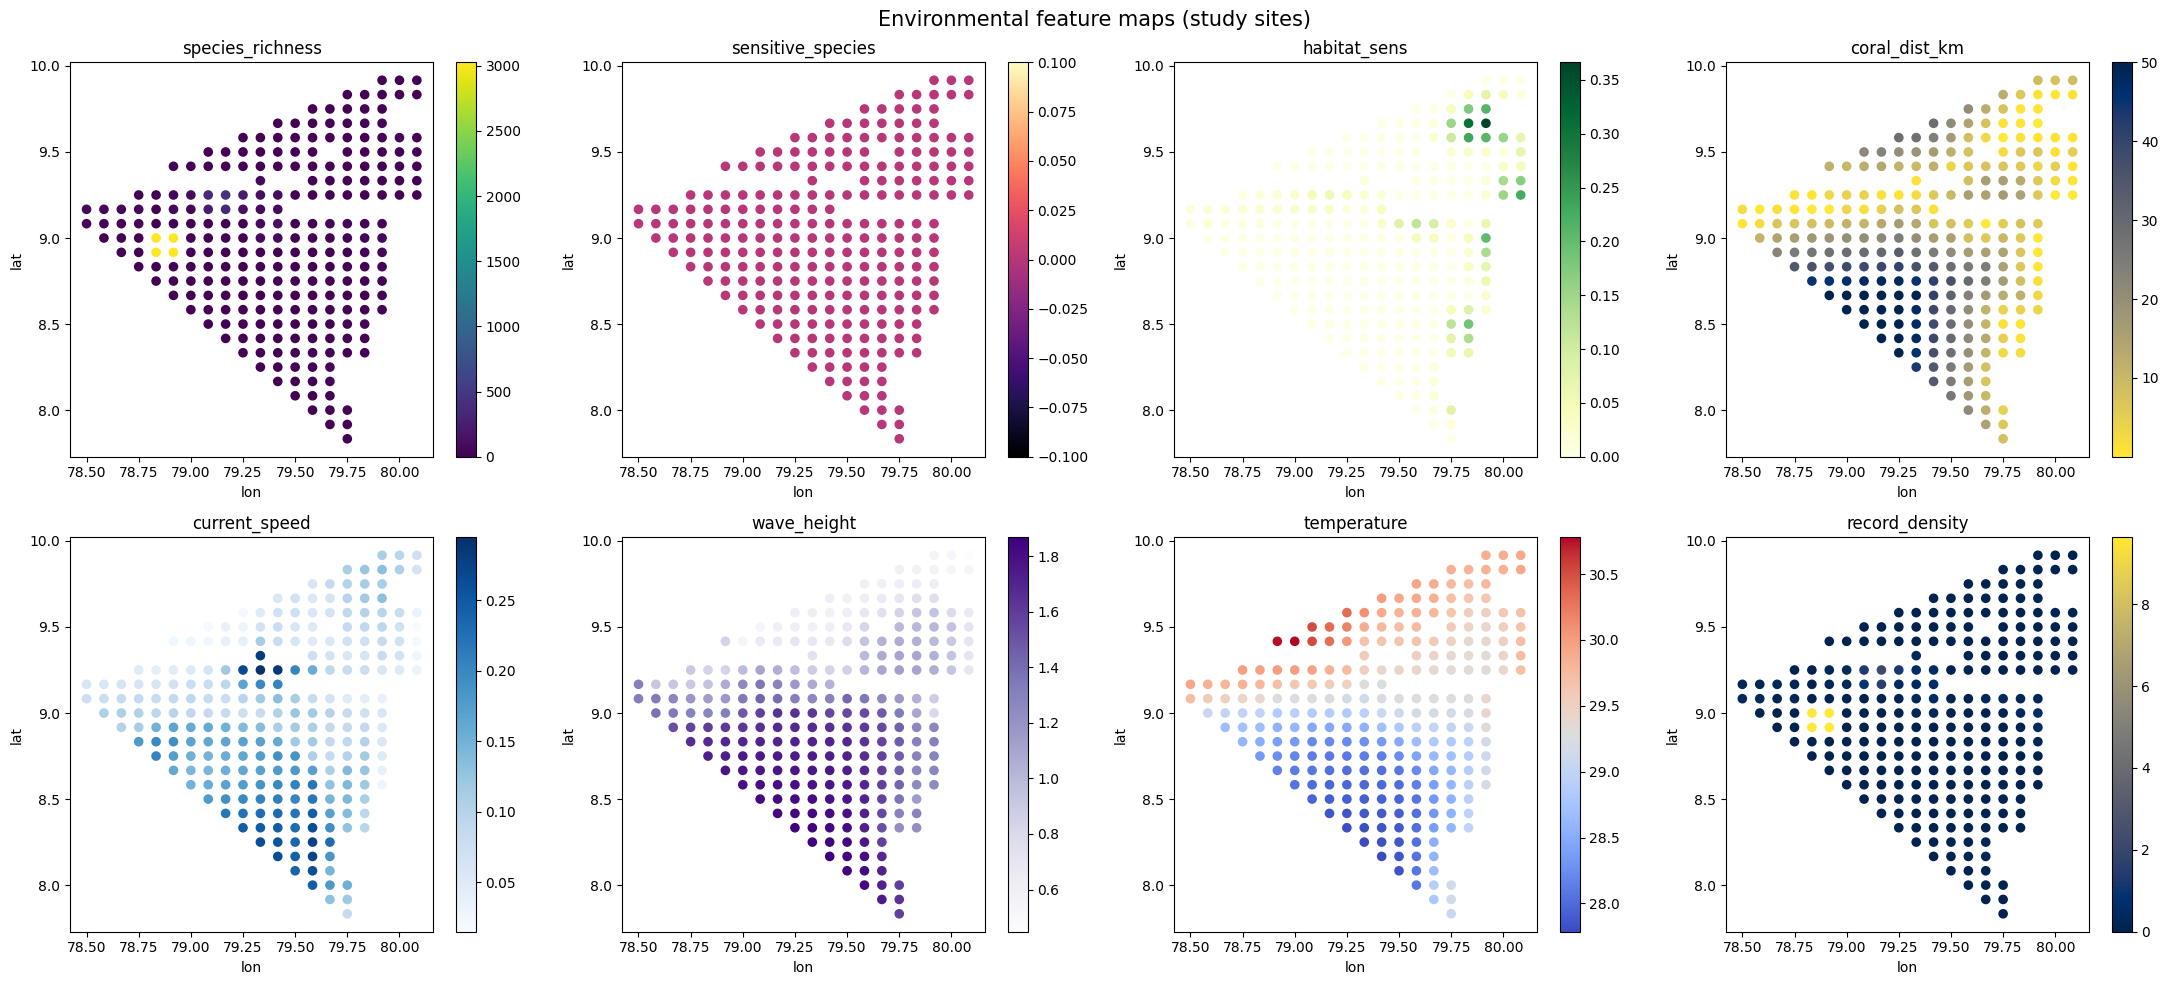

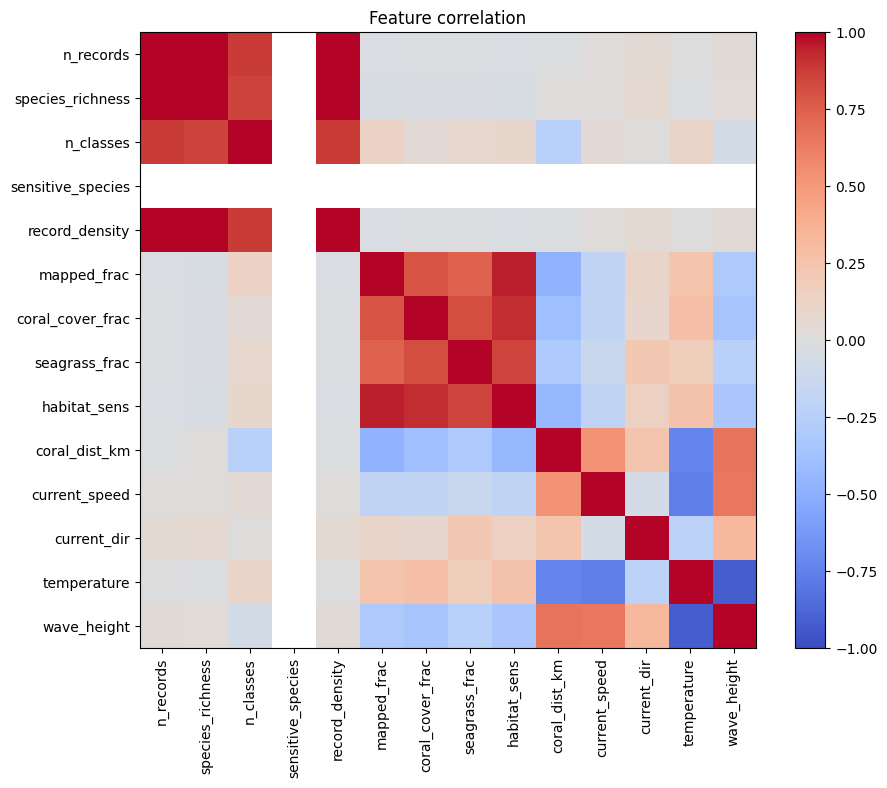

In [14]:
assert "bio_feats" in globals(), "Run the OBIS feature cell (Cell 7) first."

mean_dir = (np.degrees(np.arctan2(U.mean(0), V.mean(0))) + 360) % 360      # direction the water flows TOWARD (0 = north)
static = pd.concat([sites, bio_feats, coral_feats], axis=1)
static["current_speed"] = SPEED.mean(0)
static["current_dir"]   = mean_dir
static["temperature"]   = T.mean(0)
static["wave_height"]   = W.mean(0)
static.to_csv(f"{PROC}/site_features.csv", index=False)
print("master site table:", static.shape)
display(static.head())

# ---- quick look at every feature ----
fig, ax = plt.subplots(2, 4, figsize=(22, 10))
for a_, col, cmap in zip(ax.ravel(),
        ["species_richness", "sensitive_species", "habitat_sens", "coral_dist_km",
         "current_speed", "wave_height", "temperature", "record_density"],
        ["viridis", "magma", "YlGn", "cividis_r", "Blues", "Purples", "coolwarm", "cividis"]):
    s = a_.scatter(static.lon, static.lat, c=static[col], cmap=cmap, s=35); plt.colorbar(s, ax=a_)
    a_.set_title(col); a_.set_xlabel("lon"); a_.set_ylabel("lat")
plt.suptitle("Environmental feature maps (study sites)", fontsize=15); plt.tight_layout(); savefig("03_feature_maps")

num = static.drop(columns=["site_id", "lat", "lon"])
plt.figure(figsize=(10, 8))
plt.imshow(num.corr(), cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(num.shape[1]), num.columns, rotation=90); plt.yticks(range(num.shape[1]), num.columns)
plt.title("Feature correlation"); savefig("04_correlation")

top 10 highest-risk sites:


,site_id,lat,lon,value_score,exposure_score,plastic_risk,risk_score,risk_rank
102,S102,8.916672,78.916687,0.300000,0.676880,0.0,0.450627,1
101,S101,8.916672,78.833344,0.300000,0.643864,0.0,0.439500,2
119,S119,9.000000,78.916687,0.300000,0.455489,0.0,0.369658,3
118,S118,9.000000,78.833344,0.300000,0.434754,0.0,0.361147,4
231,S231,9.666672,79.916687,0.402775,0.318189,0.0,0.357993,5
230,S230,9.666672,79.833344,0.335238,0.295479,0.0,0.314732,6
44,S044,8.500000,79.833344,0.208227,0.413894,0.0,0.293572,7
221,S221,9.583336,79.833344,0.253602,0.325867,0.0,0.287473,8
222,S222,9.583336,79.916687,0.231281,0.320628,0.0,0.272316,9
43,S043,8.500000,79.750000,0.134341,0.551114,0.0,0.272099,10


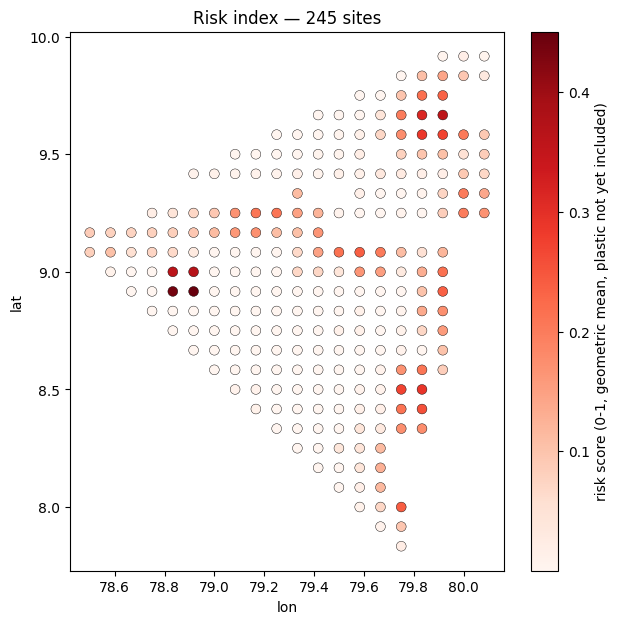

In [15]:
def normalize(s):
    """0-1 scale; a constant column becomes all zeros rather than dividing by zero."""
    rng = s.max() - s.min()
    return (s - s.min()) / rng if rng > 0 else s * 0

# ---- ecological value: how much is worth protecting at this site ----
VALUE_W = {"species_richness": 0.3, "sensitive_species": 0.3, "habitat_sens": 0.4}

# ---- physical exposure: proxies for pollutant transport/disturbance (no plastic data yet) ----
EXPOSURE_W = {"current_speed": 0.5, "wave_height": 0.5}

value_norm    = pd.DataFrame({k: normalize(static[k]) for k in VALUE_W})
exposure_norm = pd.DataFrame({k: normalize(static[k]) for k in EXPOSURE_W})

value_score    = sum(value_norm[k] * w for k, w in VALUE_W.items())
exposure_score = sum(exposure_norm[k] * w for k, w in EXPOSURE_W.items())

# plastic_risk: stub for later. Once you have per-site plastic data, normalize it here
# and fold it in as a third multiplied term (e.g. (value * exposure * plastic) ** (1/3)).
plastic_risk = pd.Series(0.0, index=static.index)

# ---- multiplicative: a site only scores high risk if BOTH value and exposure are high ----
# tiny floor avoids a hard zero wiping out a site that's otherwise borderline
risk_score = np.sqrt((value_score + 1e-6) * (exposure_score + 1e-6))

risk = static[["site_id", "lat", "lon"]].copy()
risk["value_score"] = value_score
risk["exposure_score"] = exposure_score
risk["plastic_risk"] = plastic_risk
risk["risk_score"] = risk_score
risk["risk_rank"] = risk_score.rank(ascending=False).astype(int)   # 1 = highest risk

risk.to_csv(f"{PROC}/risk_index.csv", index=False)
print("top 10 highest-risk sites:")
display(risk.sort_values("risk_score", ascending=False).head(10))

plt.figure(figsize=(7, 7))
sc = plt.scatter(risk.lon, risk.lat, c=risk.risk_score, cmap="Reds", s=50, edgecolor="k", linewidth=.3)
plt.colorbar(sc, label="risk score (0-1, geometric mean, plastic not yet included)")
plt.xlabel("lon"); plt.ylabel("lat"); plt.title(f"Risk index — {len(risk)} sites")
savefig("05_risk_index")

Spearman correlation with the default-weight ranking, across 500 random weight draws:
  mean 0.991 | 5th pct 0.968 | min 0.877


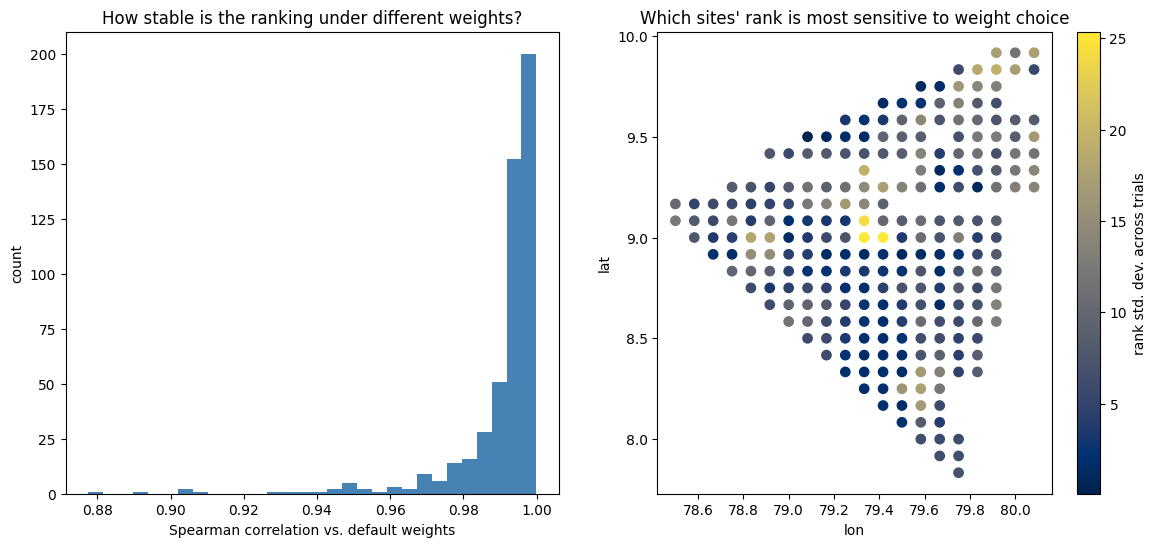

In [16]:
N_TRIALS = 500
rng = np.random.default_rng(SEED)

def random_weights(keys, rng):
    """Dirichlet gives random weights that sum to 1, so every trial is a valid weighting."""
    draws = rng.dirichlet(np.ones(len(keys)))
    return dict(zip(keys, draws))

base_rank = risk.set_index("site_id")["risk_score"].rank(ascending=False)
corrs, rank_matrix = [], []

for _ in range(N_TRIALS):
    vw = random_weights(list(VALUE_W), rng)
    ew = random_weights(list(EXPOSURE_W), rng)
    v = sum(value_norm[k] * w for k, w in vw.items())
    e = sum(exposure_norm[k] * w for k, w in ew.items())
    trial_score = np.sqrt((v + 1e-6) * (e + 1e-6))
    trial_rank = trial_score.rank(ascending=False)
    corrs.append(base_rank.corr(trial_rank.set_axis(static.site_id), method="spearman"))
    rank_matrix.append(trial_rank.values)

rank_matrix = np.array(rank_matrix)
rank_std = rank_matrix.std(axis=0)   # how much each site's rank jumps around across trials

print(f"Spearman correlation with the default-weight ranking, across {N_TRIALS} random weight draws:")
print(f"  mean {np.mean(corrs):.3f} | 5th pct {np.percentile(corrs, 5):.3f} | min {np.min(corrs):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].hist(corrs, bins=30, color="steelblue")
ax[0].set_title("How stable is the ranking under different weights?")
ax[0].set_xlabel("Spearman correlation vs. default weights"); ax[0].set_ylabel("count")

s = ax[1].scatter(static.lon, static.lat, c=rank_std, cmap="cividis", s=45)
plt.colorbar(s, ax=ax[1], label="rank std. dev. across trials")
ax[1].set_title("Which sites' rank is most sensitive to weight choice"); ax[1].set_xlabel("lon"); ax[1].set_ylabel("lat")
savefig("06_weight_sensitivity")

In [17]:
!pip install xgboost shap -q

In [18]:
import xgboost as xgb

In [19]:
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, KFold
import numpy as np

TARGET = "species_richness"
FEATURES = ["current_speed", "wave_height", "temperature",
            "habitat_sens", "coral_cover_frac", "seagrass_frac", "coral_dist_km"]
X = static[FEATURES]
y_log = np.log1p(static[TARGET])

In [20]:
print("static" in dir())
print("xgb" in dir())
print("TARGET" in dir())

True
True
True


In [21]:
from sklearn.model_selection import KFold, cross_val_score
TARGET = "species_richness"
FEATURES = ["current_speed", "wave_height", "temperature",
            "habitat_sens", "coral_cover_frac", "seagrass_frac", "coral_dist_km"]
X = static[FEATURES]
y = static[TARGET]
y_log = np.log1p(static[TARGET])   # compresses the effect of high-richness outlier sites

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
model = xgb.XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8, random_state=SEED)

cv_scores = cross_val_score(model, X, y_log, cv=kf, scoring="r2")
print(f"5-fold CV R² (shuffled, log target): mean {cv_scores.mean():.3f} | scores {np.round(cv_scores, 3)}")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, static[TARGET], test_size=0.2, random_state=SEED)

model.fit(X_train, np.log1p(y_train))
print(f"Test-set R² (log space): {model.score(X_test, np.log1p(y_test)):.3f}")

5-fold CV R² (shuffled, log target): mean 0.385 | scores [0.179 0.444 0.28  0.426 0.595]
Test-set R² (log space): 0.157


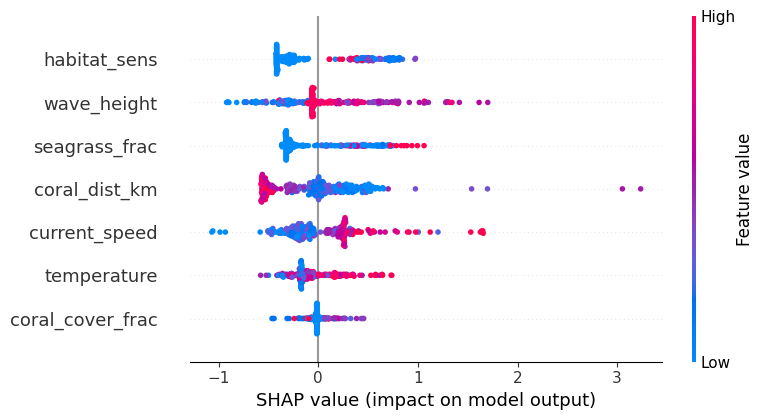

mean |SHAP value| per feature (higher = more influence on predicted richness):
habitat_sens        0.411
wave_height         0.359
seagrass_frac       0.350
coral_dist_km       0.331
current_speed       0.303
temperature         0.192
coral_cover_frac    0.060
dtype: float32


In [22]:
import shap

model_final = xgb.XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                                subsample=0.8, colsample_bytree=0.8, random_state=SEED)
model_final.fit(X, y_log)   # fit on all 245 sites for the explanation (not just the train split)

explainer = shap.TreeExplainer(model_final)
shap_values = explainer.shap_values(X)

shap.summary_plot(shap_values, X, show=False)
plt.tight_layout(); savefig("08_shap_summary")

importance = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print("mean |SHAP value| per feature (higher = more influence on predicted richness):")
print(importance.round(3))

static["shap_sum"] = shap_values.sum(axis=1)   # per-site total pull away from baseline

In [23]:
static["predicted_richness"] = np.expm1(model_final.predict(X))
static["richness_residual"] = static["species_richness"] - static["predicted_richness"]

print(static[["site_id", "species_richness", "predicted_richness", "richness_residual"]]
      .sort_values("richness_residual").head(10))

    site_id  species_richness  predicted_richness  richness_residual
5      S005                14           30.121552         -16.121552
179    S179                74           89.563782         -15.563782
156    S156                44           57.669384         -13.669384
150    S150                47           53.474937          -6.474937
54     S054                14           19.996147          -5.996147
155    S155                43           48.756752          -5.756752
209    S209                 7           12.249010          -5.249010
34     S034                10           15.137839          -5.137839
69     S069                 5            9.865677          -4.865677
83     S083                 6           10.279272          -4.279272


learned value weights:    {'habitat_sens': 0.357, 'seagrass_frac': 0.304, 'coral_cover_frac': 0.052, 'coral_dist_km': 0.287}
learned exposure weights: {'current_speed': 0.355, 'wave_height': 0.42, 'temperature': 0.225}

top 10 highest-impact sites:


,site_id,lat,lon,value_score,exposure_score,biodiversity_deficit,marine_pollution_impact_score,impact_rank
5,S005,8.000000,79.750000,0.432888,0.614971,1.000000,67.1,1
231,S231,9.666672,79.916687,0.999156,0.378492,0.000000,61.5,2
230,S230,9.666672,79.833344,0.778115,0.362274,0.249661,57.1,3
221,S221,9.583336,79.833344,0.677640,0.385399,0.119066,52.9,4
179,S179,9.333336,79.333344,0.298930,0.559533,0.965402,52.7,5
222,S222,9.583336,79.916687,0.705834,0.379764,0.000000,51.8,6
114,S114,8.916672,79.916687,0.574811,0.408374,0.101291,49.9,7
34,S034,8.416672,79.833344,0.460729,0.439252,0.318694,49.3,8
156,S156,9.166672,79.000000,0.297442,0.457224,0.847895,46.3,9
54,S054,8.583336,79.750000,0.336675,0.512114,0.371934,46.2,11


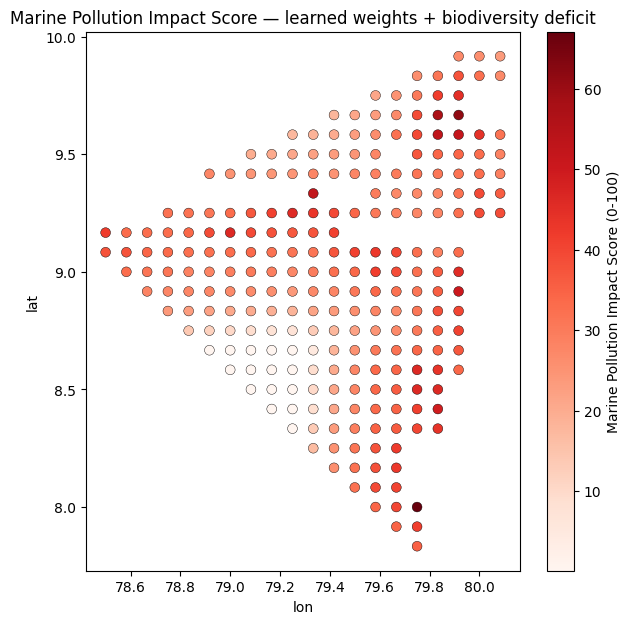

In [24]:
# ---- split into value (habitat/biodiversity-supporting) vs exposure (physical) ----
VALUE_FEATS    = ["habitat_sens", "seagrass_frac", "coral_cover_frac", "coral_dist_km"]
EXPOSURE_FEATS = ["current_speed", "wave_height", "temperature"]

feat_norm = static[FEATURES].copy()
feat_norm["coral_dist_km"] = 1 - normalize(static["coral_dist_km"])   # closer = higher value
for c in [f for f in FEATURES if f != "coral_dist_km"]:
    feat_norm[c] = normalize(static[c])

# ---- SHAP importance -> weights, normalized to sum to 1 within each group ----
value_w    = (importance[VALUE_FEATS] / importance[VALUE_FEATS].sum()).to_dict()
exposure_w = (importance[EXPOSURE_FEATS] / importance[EXPOSURE_FEATS].sum()).to_dict()
print("learned value weights:   ", {k: round(v, 3) for k, v in value_w.items()})
print("learned exposure weights:", {k: round(v, 3) for k, v in exposure_w.items()})

value_learned    = sum(feat_norm[k] * w for k, w in value_w.items())
exposure_learned = sum(feat_norm[k] * w for k, w in exposure_w.items())

# ---- fold in the model's own residual: sites with less biodiversity than conditions predict ----
# a real, observed signal that something may be suppressing biodiversity beyond what habitat/exposure explain
deficit = normalize((-static["richness_residual"]).clip(lower=0))   # only negative residuals count
base_score = np.sqrt((value_learned + 1e-6) * (exposure_learned + 1e-6))
final_score = np.clip(base_score * (1 + 0.3 * deficit), 0, 1)       # up to +30% for sites underperforming their conditions

impact = static[["site_id", "lat", "lon"]].copy()
impact["value_score"] = value_learned
impact["exposure_score"] = exposure_learned
impact["biodiversity_deficit"] = deficit
impact["marine_pollution_impact_score"] = (final_score * 100).round(1)   # 0-100
impact["impact_rank"] = impact["marine_pollution_impact_score"].rank(ascending=False).astype(int)

impact.to_csv(f"{PROC}/marine_pollution_impact_score.csv", index=False)
print("\ntop 10 highest-impact sites:")
display(impact.sort_values("marine_pollution_impact_score", ascending=False).head(10))

plt.figure(figsize=(7, 7))
sc = plt.scatter(impact.lon, impact.lat, c=impact.marine_pollution_impact_score, cmap="Reds", s=50, edgecolor="k", linewidth=.3)
plt.colorbar(sc, label="Marine Pollution Impact Score (0-100)")
plt.xlabel("lon"); plt.ylabel("lat"); plt.title("Marine Pollution Impact Score — learned weights + biodiversity deficit")
savefig("09_impact_score")

In [25]:
from sklearn.model_selection import RandomizedSearchCV, KFold
import numpy as np

param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [1, 5, 10],
}

outer_kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
outer_scores = []

for fold, (train_idx, test_idx) in enumerate(outer_kf.split(X)):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y_log.iloc[train_idx], y_log.iloc[test_idx]

    inner_kf = KFold(n_splits=4, shuffle=True, random_state=SEED)
    search = RandomizedSearchCV(
        xgb.XGBRegressor(random_state=SEED),
        param_distributions=param_dist,
        n_iter=40, cv=inner_kf, scoring="r2", random_state=SEED, n_jobs=-1
    )
    search.fit(X_tr, y_tr)
    outer_scores.append(search.score(X_te, y_te))
    print(f"fold {fold}: R² = {outer_scores[-1]:.3f} | best params: {search.best_params_}")

print(f"\nnested CV R²: mean {np.mean(outer_scores):.3f} | scores {np.round(outer_scores, 3)}")

fold 0: R² = 0.114 | best params: {'subsample': 1.0, 'reg_lambda': 10, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
fold 1: R² = 0.295 | best params: {'subsample': 0.6, 'reg_lambda': 10, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
fold 2: R² = 0.295 | best params: {'subsample': 1.0, 'reg_lambda': 10, 'reg_alpha': 1, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
fold 3: R² = 0.485 | best params: {'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
fold 4: R² = 0.435 | best params: {'subsample': 0.8, 'reg_lambda': 10, 'reg_alpha': 0.1, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.8}

nested CV R²: mean 

In [26]:
FEATURES_V2 = FEATURES + ["lat", "lon", "n_classes"]

In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

rf = RandomForestRegressor(n_estimators=300, max_depth=5, random_state=SEED)
rf_scores = cross_val_score(rf, X, y_log, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2")
print(f"Random Forest CV R²: mean {rf_scores.mean():.3f} | scores {np.round(rf_scores, 3)}")

Random Forest CV R²: mean 0.427 | scores [0.281 0.532 0.279 0.526 0.515]


In [28]:
!git clone https://github.com/wizboltez/MARIS.git

Cloning into 'MARIS'...
remote: Enumerating objects: 55, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 55 (delta 0), reused 55 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (55/55), 15.87 MiB | 6.68 MiB/s, done.


In [29]:
%cd /content/MARIS
!git checkout -b environmental-risk-module

/content/MARIS
Switched to a new branch 'environmental-risk-module'


In [31]:
!git config --global user.email "anannyajadhav06.com"
!git config --global user.name "AnannyaJadhav"

In [32]:
import shutil, os
os.makedirs("/content/MARIS/notebooks", exist_ok=True)
shutil.copy("/content/drive/MyDrive/Marine-Plastic-AI/your_notebook_name.ipynb", "/content/MARIS/notebooks/")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Marine-Plastic-AI/your_notebook_name.ipynb'